In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

df = pd.read_csv("airline_passenger_satisfaction_5000.csv")

print("Dataset shape:", df.shape)
print("\nFirst five records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)


Dataset shape: (5012, 24)

First five records:


,Passenger ID,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,1,Female,Loyal Customer,39,Personal Travel,Eco,515,2.0,2,1,...,1,3,1,1,2.0,3,3,0,0.0,neutral or dissatisfied
1,2,Male,Loyal Customer,22,Business travel,Eco,667,2.0,1,2,...,1,3,3,2,2.0,1,1,0,0.0,neutral or dissatisfied
2,3,Male,disloyal Customer,37,Personal Travel,Business,119,2.0,1,1,...,1,1,2,2,1.0,2,2,0,2.0,neutral or dissatisfied
3,4,Female,disloyal Customer,26,Business travel,Eco,380,2.0,3,2,...,2,4,1,2,3.0,3,2,0,3.0,neutral or dissatisfied
4,5,Female,Loyal Customer,35,Personal Travel,Business,3909,3.0,4,3,...,4,3,4,5,3.0,3,3,23,23.0,satisfied



Column names:
['Passenger ID', 'Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'satisfaction']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5012 entries, 0 to 5011
Data columns (total 24 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Passenger ID                       5012 non-null   int64  
 1   Gender                             5012 non-null   object 
 2   Customer Type                      5012 non-null   object 
 3   Age                                5012 non-null   int64  
 4 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Passenger ID,5012.0,NaN,NaN,NaN,2498.180367,1443.289134,1.0,1248.75,2496.5,3747.25,5000.0
Gender,5012,2,Female,2536,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Type,5012,2,Loyal Customer,3959,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,5012.0,NaN,NaN,NaN,39.011373,13.223033,18.0,29.0,38.0,48.0,80.0
Type of Travel,5012,2,Business travel,3236,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Class,5012,6,Business,2307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Flight Distance,5012.0,NaN,NaN,NaN,1142.37929,771.970547,50.0,572.0,979.0,1527.25,5000.0
Inflight wifi service,4977.0,NaN,NaN,NaN,3.322885,1.189967,1.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,5012.0,NaN,NaN,NaN,3.31684,1.199253,1.0,2.0,3.0,4.0,5.0
Ease of Online booking,5012.0,NaN,NaN,NaN,3.328212,1.182684,1.0,2.0,3.0,4.0,5.0


In [ ]:

print("Missing values in each column:")
print(df.isnull().sum().sort_values(ascending=False))


Missing values in each column:
Inflight wifi service                35
Checkin service                      35
Seat comfort                         35
Food and drink                       35
Arrival Delay in Minutes             18
Passenger ID                          0
Customer Type                         0
Gender                                0
Flight Distance                       0
Class                                 0
Type of Travel                        0
Age                                   0
Gate location                         0
Online boarding                       0
Ease of Online booking                0
Departure/Arrival time convenient     0
On-board service                      0
Inflight entertainment                0
Baggage handling                      0
Leg room service                      0
Inflight service                      0
Cleanliness                           0
Departure Delay in Minutes            0
satisfaction                          0
dtype: in

In [ ]:

before = len(df)

df = df.drop_duplicates().copy()

print("Rows before cleaning:", before)
print("Rows after duplicate removal:", len(df))
print("Duplicates remaining:", df.duplicated().sum())


Rows before cleaning: 5012
Rows after duplicate removal: 5000
Duplicates remaining: 0


In [ ]:

df["Class"] = (
    df["Class"]
    .astype("string")
    .str.strip()
    .str.title()
)

print(df["Class"].value_counts())


Class
Business    2312
Eco         2175
Eco Plus     513
Name: count, dtype: Int64


In [ ]:

target = "satisfaction"

# Fill missing numerical input values
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values, excluding the target
categorical_cols = df.select_dtypes(
    include=["object", "string", "category"]
).columns.drop(target, errors="ignore")

for col in categorical_cols:
    if df[col].notna().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values remaining:", df.isnull().sum().sum())


Missing values remaining: 0


In [ ]:

delay_cols = [
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

for col in delay_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = max(0, q1 - 1.5 * iqr)
    upper = q3 + 1.5 * iqr

    outliers = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: {outliers} outliers detected")

    df[col] = df[col].clip(lower=lower, upper=upper)

print("Outlier treatment completed.")


Departure Delay in Minutes: 692 outliers detected
Arrival Delay in Minutes: 435 outliers detected
Outlier treatment completed.


satisfaction
satisfied                  3338
neutral or dissatisfied    1662
Name: count, dtype: int64


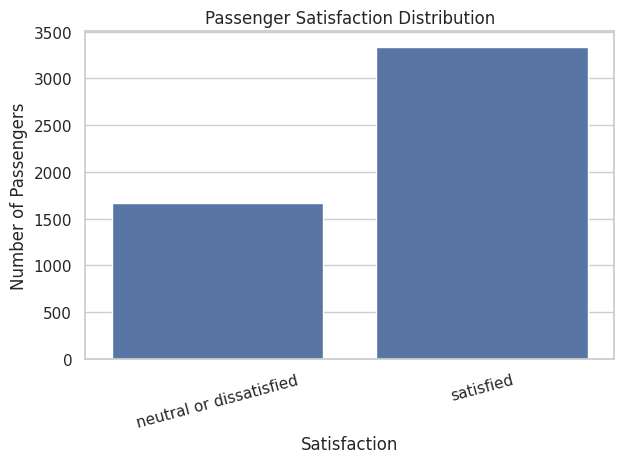

In [ ]:

print(df["satisfaction"].value_counts())

sns.countplot(data=df, x="satisfaction")
plt.title("Passenger Satisfaction Distribution")
plt.xlabel("Satisfaction")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


Average service ratings:


,Average Rating
On-board service,3.3160
Food and drink,3.3162
Baggage handling,3.3176
Seat comfort,3.3208
Inflight wifi service,3.3214
Cleanliness,3.3216
Checkin service,3.3312


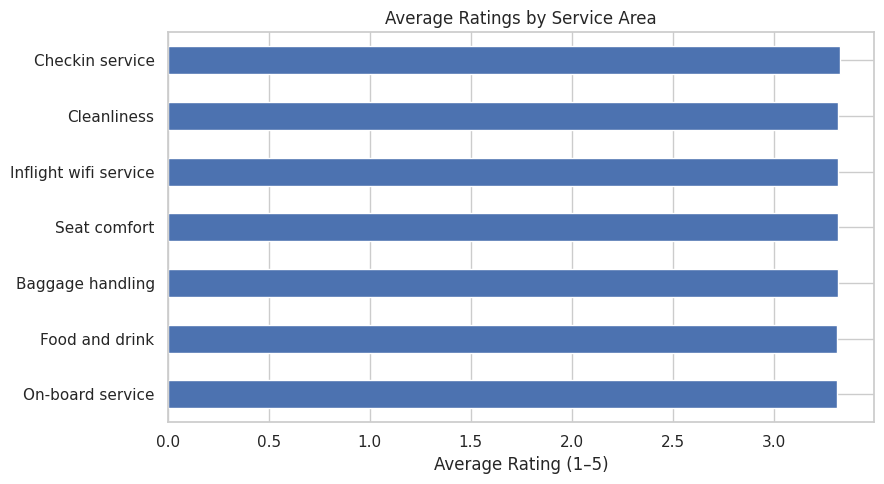

Lowest-rated service: On-board service
Highest-rated service: Checkin service


In [ ]:

service_cols = [
    "Inflight wifi service",
    "Food and drink",
    "Seat comfort",
    "On-board service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness"
]

service_means = df[service_cols].mean().sort_values()

print("Average service ratings:")
display(service_means.to_frame("Average Rating"))

service_means.plot(kind="barh", figsize=(9, 5))
plt.title("Average Ratings by Service Area")
plt.xlabel("Average Rating (1–5)")
plt.tight_layout()
plt.show()

print("Lowest-rated service:", service_means.idxmin())
print("Highest-rated service:", service_means.idxmax())


,Departure Delay in Minutes,Arrival Delay in Minutes
satisfaction,,
neutral or dissatisfied,9.998195,13.533694
satisfied,4.030557,6.213901


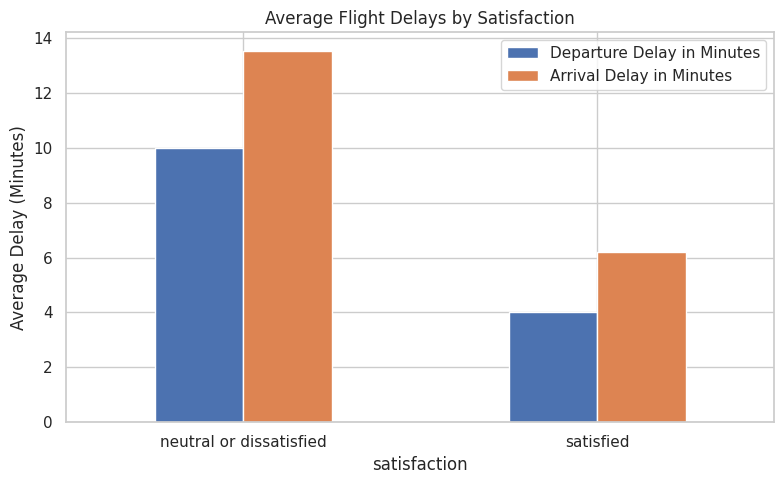

In [ ]:

delay_summary = df.groupby("satisfaction")[
    delay_cols
].mean()

display(delay_summary)

delay_summary.plot(kind="bar", figsize=(8, 5))
plt.title("Average Flight Delays by Satisfaction")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


satisfaction,neutral or dissatisfied,satisfied
Class,,
Business,24.26,75.74
Eco,40.78,59.22
Eco Plus,41.72,58.28


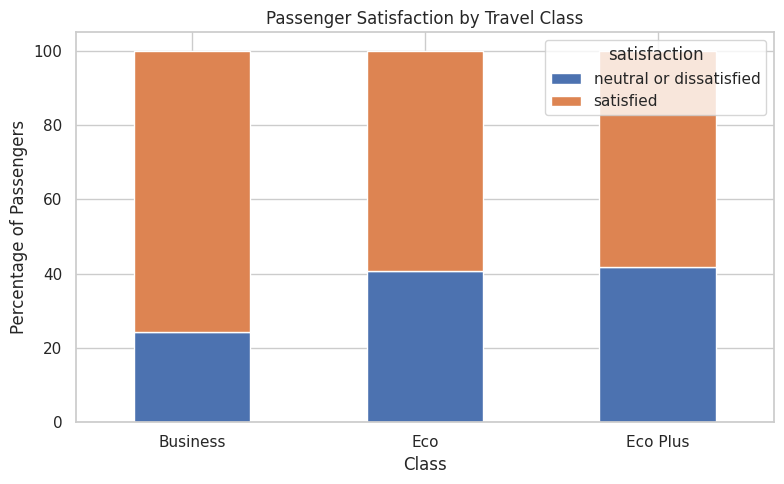

In [ ]:

class_satisfaction = pd.crosstab(
    df["Class"],
    df["satisfaction"],
    normalize="index"
) * 100

display(class_satisfaction.round(2))

class_satisfaction.plot(
    kind="bar", stacked=True, figsize=(8, 5)
)
plt.title("Passenger Satisfaction by Travel Class")
plt.ylabel("Percentage of Passengers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

print("EDA FINDINGS")

print(
    "1. Lowest-rated service:",
    service_means.idxmin(),
    "with average rating",
    round(service_means.min(), 2)
)

print(
    "2. Satisfaction distribution (%):"
)

print(
    (df["satisfaction"].value_counts(normalize=True) * 100)
    .round(2)
)


EDA FINDINGS
1. Lowest-rated service: On-board service with average rating 3.32
2. Satisfaction distribution (%):
satisfaction
satisfied                  66.76
neutral or dissatisfied    33.24
Name: proportion, dtype: float64


In [ ]:

target = "satisfaction"

features = [
    "Gender",
    "Customer Type",
    "Age",
    "Type of Travel",
    "Class",
    "Flight Distance",
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Inflight service",
    "Cleanliness",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

X = df[features].copy()
y = df[target].copy()

print("Number of input features:", len(features))
print("Target variable:", target)
print("Input shape:", X.shape)
print("Target shape:", y.shape)


Number of input features: 21
Target variable: satisfaction
Input shape: (5000, 21)
Target shape: (5000,)


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 4000
Testing records: 1000


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

num_features = X.select_dtypes(include="number").columns.tolist()
cat_features = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_features),
    ("cat", categorical_pipeline, cat_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


Accuracy : 0.8150 (81.50%)
Precision: 0.8112
Recall   : 0.8150
F1-score : 0.8105

Classification Report:
                         precision    recall  f1-score   support

neutral or dissatisfied       0.76      0.64      0.70       332
              satisfied       0.83      0.90      0.87       668

               accuracy                           0.81      1000
              macro avg       0.80      0.77      0.78      1000
           weighted avg       0.81      0.81      0.81      1000



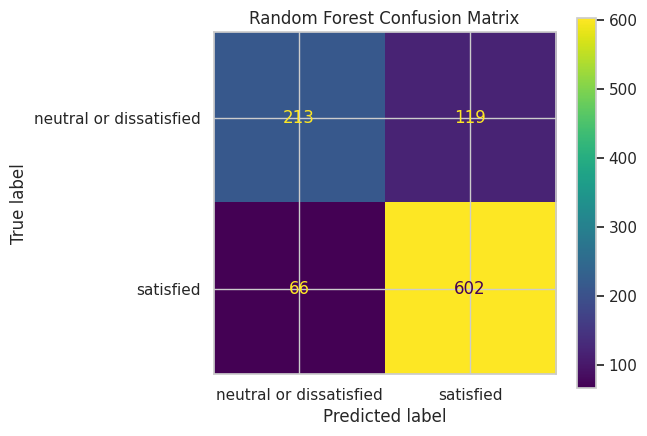

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

print(f"Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()


,Feature,Importance
16,num__Arrival Delay in Minutes,0.090051
15,num__Departure Delay in Minutes,0.083077
1,num__Flight Distance,0.069178
0,num__Age,0.060034
13,num__Inflight service,0.056387
3,num__Departure/Arrival time convenient,0.051948
7,num__Seat comfort,0.051702
12,num__Checkin service,0.050816
4,num__Ease of Online booking,0.050460
2,num__Inflight wifi service,0.047382


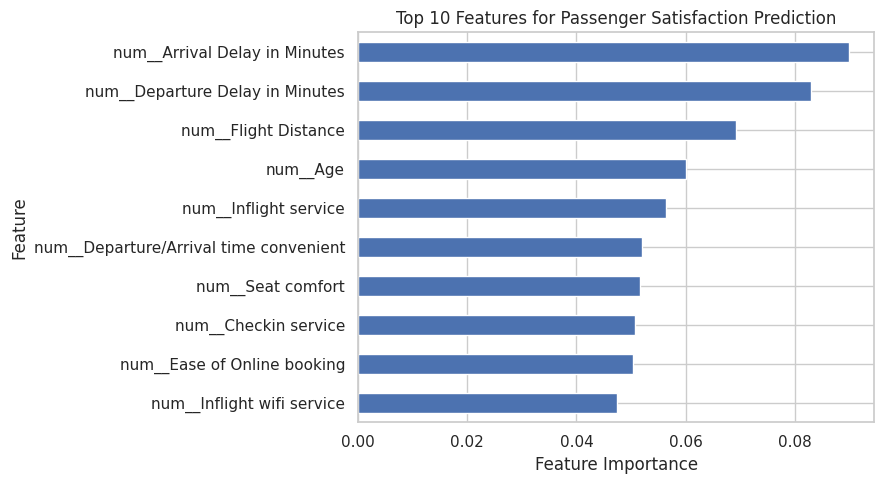

In [ ]:

feature_names = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = model.named_steps[
    "classifier"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(10))

importance_df.head(10).sort_values(
    "Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(9, 5),
    legend=False
)

plt.title("Top 10 Features for Passenger Satisfaction Prediction")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()


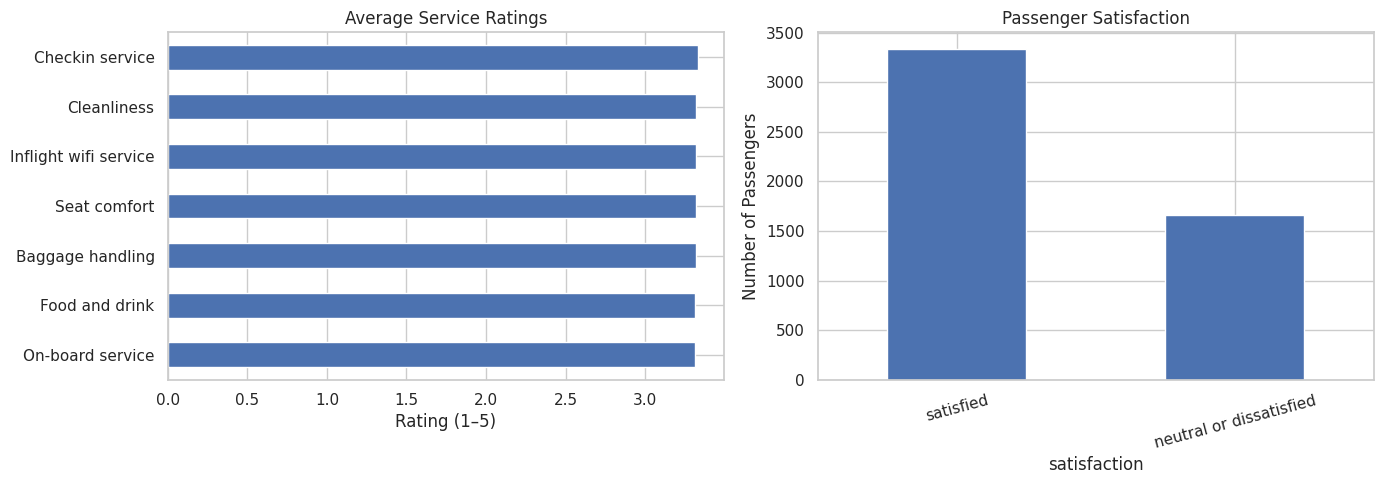

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Service ratings
service_means.sort_values().plot(
    kind="barh", ax=axes[0]
)
axes[0].set_title("Average Service Ratings")
axes[0].set_xlabel("Rating (1–5)")

# Chart 2: Satisfaction distribution
df["satisfaction"].value_counts().plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Passenger Satisfaction")
axes[1].set_ylabel("Number of Passengers")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


satisfaction,neutral or dissatisfied,satisfied
Customer Type,,
Loyal Customer,29.89,70.11
disloyal Customer,45.85,54.15


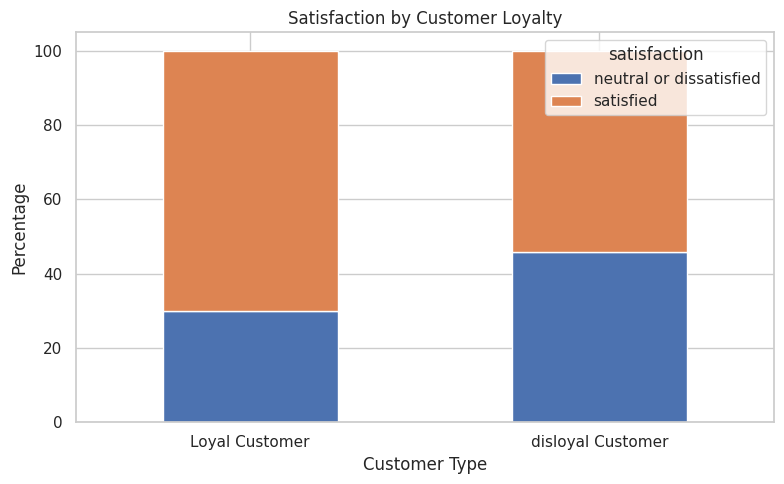

In [ ]:

loyalty_summary = pd.crosstab(
    df["Customer Type"],
    df["satisfaction"],
    normalize="index"
) * 100

display(loyalty_summary.round(2))

loyalty_summary.plot(
    kind="bar", stacked=True, figsize=(8, 5)
)
plt.title("Satisfaction by Customer Loyalty")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

travel_summary = pd.crosstab(
    df["Type of Travel"],
    df["satisfaction"],
    normalize="index"
) * 100

display(travel_summary.round(2))


satisfaction,neutral or dissatisfied,satisfied
Type of Travel,,
Business travel,30.79,69.21
Personal Travel,37.69,62.31


In [ ]:

output_file = "cleaned_airline_passenger_data.csv"

df.to_csv(output_file, index=False)

print("Cleaned dataset saved:", output_file)

from google.colab import files
files.download(output_file)


Cleaned dataset saved: cleaned_airline_passenger_data.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>